# 03 — DP-SGD: what changes when we add privacy?

Three pilots are completed at target epsilon 1, 4 and 8. This notebook reads saved results and never retrains by itself. The same employment target, 77 inputs, hidden widths 64/32, SGD learning rate, 20 epochs and development records match the baseline.

DP-SGD clips each person's gradient and adds Gaussian noise. Opacus tracks the resulting (epsilon, delta) bound. Smaller epsilon means stronger privacy at fixed delta. These are single-run development results; repeated runs are needed for conclusions.

See [the training log](../dp_training_log.md) for the full record. Test outcomes remain reserved.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'proposal.md').exists())
RUN=ROOT/'results/dp_pilot'
comparison=pd.read_csv(RUN/'comparison.csv')
summaries=[json.loads(p.read_text()) for p in sorted(RUN.glob('epsilon_*/summary.json'))]
display(pd.DataFrame([{k:s[k] for k in ['target_epsilon','epsilon','delta','noise_multiplier','max_grad_norm','sample_rate','expected_batch_size','steps']} for s in summaries]))

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\CiciA\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


,target_epsilon,epsilon,delta,noise_multiplier,max_grad_norm,sample_rate,expected_batch_size,steps
0,1.0,0.999160,6.608512e-07,1.411133,1.0,0.003378,511,5920
1,4.0,3.999411,6.608512e-07,0.740509,1.0,0.003378,511,5920
2,8.0,7.999651,6.608512e-07,0.597458,1.0,0.003378,511,5920


## 1. Read the privacy settings

target_epsilon is requested; epsilon is the accountant's achieved bound after training. Delta is fixed at approximately 6.61e-7. max_grad_norm=1 is the clipping norm, and noise_multiplier determines added noise relative to that norm. sample_rate is the per-person inclusion probability at each step. steps counts updates, including the accountant's updates.

Poisson sampling makes batch sizes variable. Each epoch is a fixed number of sampling steps. It does not guarantee visiting every person once. The reference scaler and encoder remain unchanged.

,method,target_epsilon,epsilon,accuracy,balanced_accuracy,accuracy_loss_pp
0,SGD,NaN,NaN,0.770784,0.757322,0.000000
1,DP-SGD,1.0,0.999160,0.758195,0.736713,1.258921
2,DP-SGD,4.0,3.999411,0.758128,0.736891,1.265530
3,DP-SGD,8.0,7.999651,0.757798,0.736299,1.298573


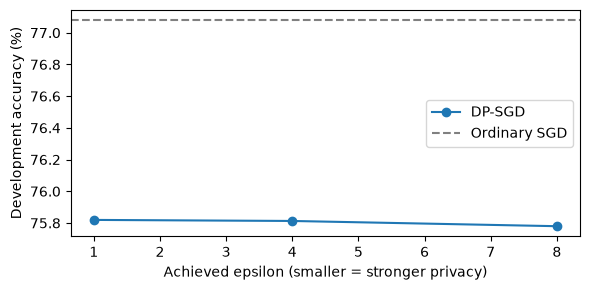

In [2]:
columns=['method','target_epsilon','epsilon','accuracy','balanced_accuracy','accuracy_loss_pp']
display(comparison[columns])
private=comparison.loc[comparison.method.eq('DP-SGD')].sort_values('epsilon')
baseline_accuracy=float(comparison.loc[comparison.method.eq('SGD'),'accuracy'].iloc[0])
fig,ax=plt.subplots(figsize=(6,3))
ax.plot(private.epsilon,100*private.accuracy,marker='o',label='DP-SGD')
ax.axhline(100*baseline_accuracy,color='gray',linestyle='--',label='Ordinary SGD')
ax.set(xlabel='Achieved epsilon (smaller = stronger privacy)',ylabel='Development accuracy (%)')
ax.legend();plt.tight_layout()
FIG=ROOT/'figures/dp_pilot'
FIG.mkdir(parents=True,exist_ok=True)
fig.savefig(FIG/'accuracy_vs_epsilon.png',dpi=180,bbox_inches='tight')
plt.show()

## 2. Is the private model learning?

The table's accuracy values are fractions (0.75 means 75%). accuracy_loss_pp is baseline minus private accuracy in percentage points. Compare the learning curves below to see whether each model is improving or still learning at the fixed final epoch.

We deliberately do not log raw private-training losses. Development evaluation uses the designated public auxiliary partition.

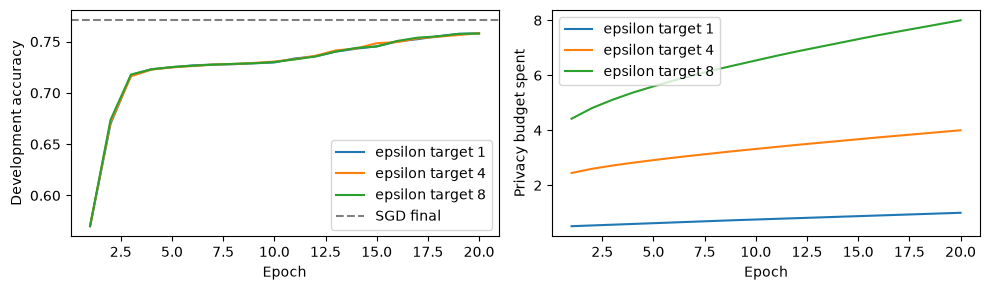

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3))
for s in summaries:
    h=pd.read_csv(RUN/f"epsilon_{s['target_epsilon']:g}"/'history.csv')
    axes[0].plot(h.epoch,h.development_accuracy,label=f"epsilon target {s['target_epsilon']:g}")
    axes[1].plot(h.epoch,h.epsilon,label=f"epsilon target {s['target_epsilon']:g}")
axes[0].axhline(baseline_accuracy,color='gray',linestyle='--',label='SGD final')
axes[0].set(xlabel='Epoch',ylabel='Development accuracy')
axes[1].set(xlabel='Epoch',ylabel='Privacy budget spent')
for ax in axes: ax.legend()
plt.tight_layout()
FIG=ROOT/'figures/dp_pilot'
FIG.mkdir(parents=True,exist_ok=True)
fig.savefig(FIG/'learning_and_privacy.png',dpi=180,bbox_inches='tight')
plt.show()

## 3. Which groups lost accuracy?

These are model accuracy losses, not differences in label base rates. Positive loss means DP reduced that group's accuracy; negative means it improved it in this run. Sex codes are 1=male and 2=female. Race codes retain Census meanings from notebook 01/the processing log.

Always inspect counts and conditional denominators. Very small race/intersectional groups can have large unstable changes.

In [4]:
losses=[]
for s in summaries:
    frame=pd.read_csv(RUN/f"epsilon_{s['target_epsilon']:g}"/'group_accuracy_losses.csv',dtype={'group':str})
    frame['target_epsilon']=s['target_epsilon']
    losses.append(frame)
losses=pd.concat(losses,ignore_index=True)
columns=['target_epsilon','group','n','accuracy_sgd','accuracy_dp','accuracy_loss_pp','min_conditional_count']
display(losses.loc[losses.attribute.eq('SEX'),columns])
display(losses.loc[losses.attribute.eq('RAC1P'),columns])

,target_epsilon,group,n,accuracy_sgd,accuracy_dp,accuracy_loss_pp,min_conditional_count
0,1.0,1,14826,0.804802,0.795832,0.897073,4707
1,1.0,2,15438,0.738114,0.722049,1.606426,4781
29,4.0,1,14826,0.804802,0.795494,0.930797,4742
30,4.0,2,15438,0.738114,0.722244,1.586993,4798
58,8.0,1,14826,0.804802,0.795697,0.910563,4713
59,8.0,2,15438,0.738114,0.721402,1.671201,4773


,target_epsilon,group,n,accuracy_sgd,accuracy_dp,accuracy_loss_pp,min_conditional_count
2,1.0,1,18889,0.773307,0.760866,1.244110,6360
3,1.0,2,1500,0.797333,0.786667,1.066667,637
4,1.0,3,202,0.688119,0.678218,0.990099,77
5,1.0,4,2,1.000000,1.000000,0.000000,0
6,1.0,5,81,0.802469,0.790123,1.234568,29
7,1.0,6,5017,0.767790,0.751445,1.634443,1278
8,1.0,7,95,0.842105,0.810526,3.157895,27
9,1.0,8,3299,0.750227,0.743559,0.666869,761
10,1.0,9,1179,0.772689,0.755725,1.696353,317
31,4.0,1,18889,0.773307,0.761554,1.175287,6423


## 4. What happened to fairness gaps?

Independence compares positive-prediction rates. Separation compares true-positive and false-positive rates. Binary sufficiency compares positive/negative predictive values. Smaller gaps mean closer agreement with that criterion; group accuracy losses answer a different question.

A blank/NaN gap means a required group rate is undefined. It is not a zero gap. Rare-group rates and three randomized pilot runs do not justify a universal conclusion about fairness.

SEX


,method,target_epsilon,SEX_accuracy_gap,SEX_independence,SEX_separation,SEX_sufficiency
0,SGD,NaN,0.066689,0.006355,0.120073,0.125814
1,DP-SGD,1.0,0.073782,0.007792,0.113801,0.121242
2,DP-SGD,4.0,0.073251,0.009052,0.115064,0.121612
3,DP-SGD,8.0,0.074295,0.008715,0.115383,0.121926


RAC1P


,method,target_epsilon,RAC1P_accuracy_gap,RAC1P_independence,RAC1P_separation,RAC1P_sufficiency
0,SGD,NaN,0.311881,0.694638,NaN,NaN
1,DP-SGD,1.0,0.321782,0.769324,NaN,NaN
2,DP-SGD,4.0,0.321782,0.771749,NaN,NaN
3,DP-SGD,8.0,0.321782,0.770233,NaN,NaN


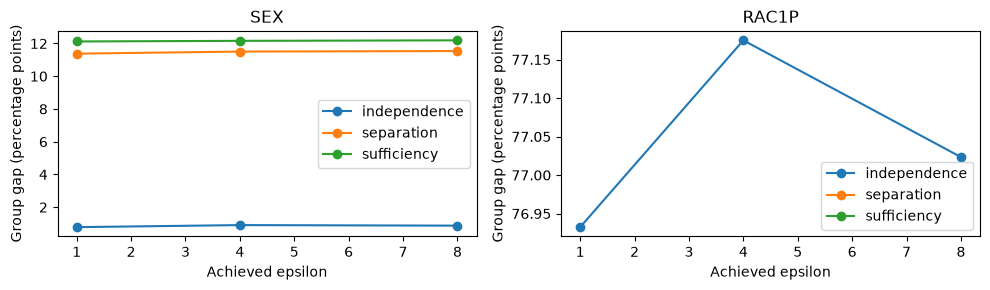

In [5]:
for attribute in ['SEX','RAC1P']:
    columns=['method','target_epsilon']+[f'{attribute}_{name}' for name in ['accuracy_gap','independence','separation','sufficiency']]
    print(attribute)
    display(comparison[columns])
fig,axes=plt.subplots(1,2,figsize=(10,3))
for ax,attribute in zip(axes,['SEX','RAC1P']):
    for name in ['independence','separation','sufficiency']:
        ax.plot(private.epsilon,100*private[f'{attribute}_{name}'],marker='o',label=name)
    ax.set(title=attribute,xlabel='Achieved epsilon',ylabel='Group gap (percentage points)')
    ax.legend()
plt.tight_layout()
FIG=ROOT/'figures/dp_pilot'
FIG.mkdir(parents=True,exist_ok=True)
fig.savefig(FIG/'fairness_gaps.png',dpi=180,bbox_inches='tight')
plt.show()

## 5. Scope and your review notes

Each reported budget belongs to one private run, conditional on public auxiliary data. A joint release of several private models requires composition. The ordinary baseline and the repository's public-data audits are not DP releases. These experiments use research RNG settings, not cryptographically hardened deployment settings.

The MLP initialization seed is fixed; sampling/noise randomness is independent and not exported. Changes may reflect clipping, noise, sampling, and random variation. We need repeated seeds and can add a sampling-matched/clipping-only diagnostic to distinguish mechanisms.

- How large is the overall accuracy cost?
- Are sex-group losses similar? Which race-group estimates have enough support?
- Does a smaller gap accompany improved performance or worse performance for another group?
- Which findings can we cautiously report now, and which need repetitions?

Training entry point: `scripts/train_dp.py`; settings: `configs/dp_pilot.json`. Do not rerun completed pilots casually: new runs are new experiments and would add privacy cost if released.